# Flujo de un fluido viscoelástico alrededor de un cilindro

Réplica del ejemplo de COMSOL *Flow of Viscoelastic Fluid Past a Cylinder* (`cylinder_flow_viscoelastic`) con la física viscoelástica del proyecto.

- Fluido Oldroyd-B (modo Giesekus con $\alpha = 0$) con solvente: $\beta = \mu_s/\mu = 0.59$, $\mu_p = 0.41$.
- Variables adimensionales con $R$, $U_{in}$ (velocidad media de entrada) y $\mu = \mu_s + \mu_p = 1$. $\mathrm{Wi} = \lambda U_{in}/R$, y como $R = U_{in} = 1$, $\lambda = \mathrm{Wi}$.
- $\mathrm{Re} = 10^{-3}$ en COMSOL; aquí Stokes (la inercia es despreciable a ese Re).
- Canal $x \in [-10, 15]$, semialtura $2R$, cilindro de radio 1 en el origen. Solo la mitad superior (simetría en $y = 0$).
- Entrada: perfil parabólico $u = \tfrac32 (1 - (y/2)^2)$ con las tensiones poliméricas desarrolladas. Salida: presión de flujo desarrollado.
- Continuación en Wi y arrastre $C_d = 2F_x/\mu$ sobre el cilindro, comparado con Hulsen et al. (2005), de la misma familia de referencias que usa COMSOL (Alves et al. 2001).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import gmsh

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.FluidFlow import ff
from Source.Physics.Viscoelastic import ve
from Source.enums import StudyType, ProblemType

In [2]:
X_IN, X_OUT, H, R = -10.0, 15.0, 2.0, 1.0      # dominio de COMSOL (mitad superior)
MU_S, MU_P = 0.59, 0.41
MU = MU_S + MU_P
SIZE_MIN, SIZE_MAX = 0.05, 0.5                   # tamano de elemento junto al cilindro y lejos
WI_STEP, WI_MAX = 0.1, 1.0                      # COMSOL llega a 1.0 con paso 0.05; con Oldroyd-B la malla manda mas alla de ~0.7

# Arrastre de Oldroyd-B, beta = 0.59, bloqueo 1/2 (Hulsen et al. 2005, tabulado en arXiv:2308.09394)
HULSEN = {0.1: 130.363, 0.2: 126.626, 0.3: 123.193, 0.4: 120.596, 0.5: 118.836, 0.6: 117.775, 0.7: 117.315, 0.8: 117.373, 0.9: 117.787, 1.0: 118.471}

In [3]:
def cylinder_mesh():

    """Triangulos cuadraticos: canal menos el cilindro, refinado alrededor de este."""

    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    try:
        occ = gmsh.model.occ
        fluid, _ = occ.cut([(2, occ.addRectangle(X_IN, 0, 0, X_OUT - X_IN, H))], [(2, occ.addDisk(0, 0, 0, R, R))])
        occ.synchronize()
        groups = {'inlet': [], 'outlet': [], 'wall': [], 'axis': [], 'cylinder': []}
        for _, tag in gmsh.model.getBoundary(fluid, oriented=False):
            x, y, _ = occ.getCenterOfMass(1, tag)
            key = ('inlet' if abs(x - X_IN) < 1e-9 else 'outlet' if abs(x - X_OUT) < 1e-9 else
                   'wall' if abs(y - H) < 1e-9 else 'axis' if abs(y) < 1e-9 else 'cylinder')
            groups[key].append(tag)
        for name, tags in groups.items():
            gmsh.model.addPhysicalGroup(1, tags, name=name)

        field = gmsh.model.mesh.field
        dist = field.add('Distance')
        field.setNumbers(dist, 'CurvesList', groups['cylinder'])
        field.setNumber(dist, 'Sampling', 200)
        threshold = field.add('Threshold')
        field.setNumber(threshold, 'InField', dist)
        field.setNumber(threshold, 'SizeMin', SIZE_MIN)
        field.setNumber(threshold, 'SizeMax', SIZE_MAX)
        field.setNumber(threshold, 'DistMin', 0.1)
        field.setNumber(threshold, 'DistMax', 2.5)
        field.setAsBackgroundMesh(threshold)
        gmsh.option.setNumber('Mesh.MeshSizeExtendFromBoundary', 0)
        gmsh.model.mesh.generate(2)
        gmsh.model.mesh.setOrder(2)
        return Mesh.from_gmsh_model()
    finally:
        gmsh.finalize()

mesh = cylinder_mesh()
xy = np.array([n.coor[:2] for n in mesh.NL], dtype=float)
triang = mesh.triangulation()
print(f"Malla: {mesh.getNoN()} nodos")

Malla: 3718 nodos


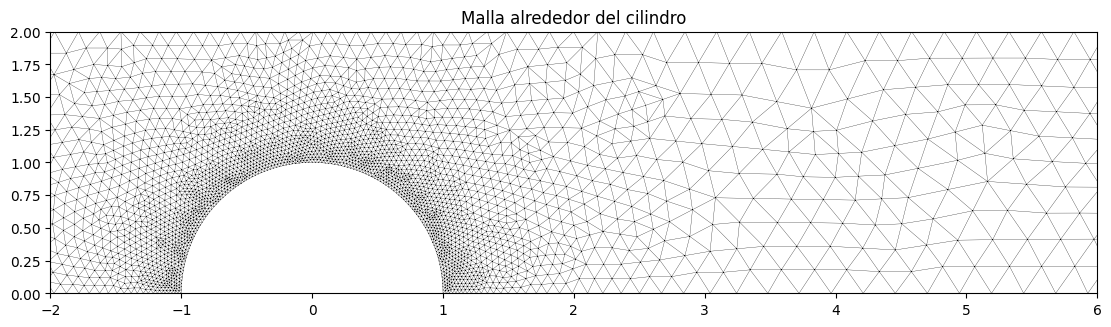

In [4]:
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.triplot(triang, lw=0.2, color='k')
ax.set_xlim(-2, 6); ax.set_ylim(0, H); ax.set_aspect('equal'); ax.set_title('Malla alrededor del cilindro')
plt.show()

## Física y condiciones de contorno

Oldroyd-B como un modo con $\alpha = 0$, DEVSS-G para recuperar la elipticidad del momento y el solvente como viscosidad del flujo. Se empieza en $\mathrm{Wi} = 0.1$ desde el campo parabólico; cada Wi siguiente parte de la solución anterior.

In [5]:
model = Model(name='cilindro_ve', dim=2, mesh=mesh, mat=material('X', miu=MU_S), psc=[ff, ve])
flow, polymer = model.physics.fluid, model.physics.viscoelastic
polymer.setModes([(MU_P, WI_STEP, 0.0)])         # (mu_p, lambda, alpha): lambda = Wi porque R = U_in = 1
polymer.setDEVSS(MU_P)

inlet, outlet, cylinder = mesh.boundary_edges('inlet'), mesh.boundary_edges('outlet'), mesh.boundary_edges('cylinder')
profile = lambda x, y: (1.5 * (1 - (y / H) ** 2), 0.0)
flow.addBC_VelocityEdges(inlet, profile)
flow.addBC_NoSlipEdges(mesh.boundary_edges('wall'))
flow.addBC_NoSlipEdges(cylinder)
flow.addBC_SymmetryEdges(mesh.boundary_edges('axis'))
flow.addBC_OutletEdges(outlet, 0.0)
polymer.addBC_OutletEdges(outlet)
# gradiente de velocidad desarrollado en la entrada (du/dy), de donde sale el esfuerzo polimerico de entrada
polymer.addBC_InflowEdges(inlet, lambda x, y: [[0.0, -1.5 * 2 * y / H ** 2], [0.0, 0.0]])
flow.var['u'].updateField(np.array([profile(*n.coor[:2]) for n in mesh.NL]))
print(f"{model.layout.ndof} incognitas")

37180 incognitas


## Continuación en Wi y arrastre

In [6]:
def drag():
    return 2.0 * flow.boundaryForce(cylinder)[0] / MU

history = {}
snapshots = {}
Wi = WI_STEP
while Wi <= WI_MAX + 1e-9:
    model.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear)
    model.solve()
    if not model.nonlinear_converged:
        print(f"Wi = {Wi:.2f}: no converge, se detiene la continuacion")
        break
    key = round(Wi, 10)
    history[key] = drag()
    snapshots[key] = {'u': np.array(model.sol['u']), 'tau': np.array(model.sol['polymer_stress'])}
    ref = HULSEN.get(round(Wi, 1))
    note = f", Hulsen {ref:.3f} ({history[key] / ref - 1:+.3%})" if ref else ""
    print(f"Wi = {Wi:.2f}: {model.newton_iterations} iteraciones, Cd = {history[key]:.3f}{note}")
    polymer.setWeissenberg((Wi + WI_STEP) / Wi)
    Wi += WI_STEP

2026-11-03 18:59:17 - INFO - ------- Starting simulation -------
2026-11-03 18:59:17 - INFO - Model: cilindro_ve
2026-11-03 18:59:17 - INFO - Dimension: 2D
2026-11-03 18:59:17 - INFO - Nodes: 3718
2026-11-03 18:59:17 - INFO - Elements: 1761
2026-11-03 18:59:17 - INFO - Physics: Creeping flow (Stokes) + Viscoelastic polymer modes
2026-11-03 18:59:17 - INFO - ------- Solver configuration -------
2026-11-03 18:59:17 - INFO - Study: Steady state
2026-11-03 18:59:17 - INFO - Type: Nonlinear
2026-11-03 18:59:17 - INFO - Method: Direct
2026-11-03 18:59:17 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-03 18:59:17 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-03 18:59:17 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-03 18:59:17 - INFO - -----------------------------------------------------------
2026-11-03 18:59:17 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11

Wi = 0.10: 7 iteraciones, Cd = 130.361, Hulsen 130.363 (-0.002%)


2026-11-03 18:59:33 - INFO - ------- Starting simulation -------
2026-11-03 18:59:33 - INFO - Model: cilindro_ve
2026-11-03 18:59:33 - INFO - Dimension: 2D
2026-11-03 18:59:33 - INFO - Nodes: 3718
2026-11-03 18:59:33 - INFO - Elements: 1761
2026-11-03 18:59:33 - INFO - Physics: Creeping flow (Stokes) + Viscoelastic polymer modes
2026-11-03 18:59:33 - INFO - ------- Solver configuration -------
2026-11-03 18:59:33 - INFO - Study: Steady state
2026-11-03 18:59:33 - INFO - Type: Nonlinear
2026-11-03 18:59:33 - INFO - Method: Direct
2026-11-03 18:59:33 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-03 18:59:33 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-03 18:59:33 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-03 18:59:33 - INFO - -----------------------------------------------------------
2026-11-03 18:59:33 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11

Wi = 0.20: 5 iteraciones, Cd = 126.623, Hulsen 126.626 (-0.002%)


2026-11-03 18:59:45 - INFO - ------- Starting simulation -------
2026-11-03 18:59:45 - INFO - Model: cilindro_ve
2026-11-03 18:59:45 - INFO - Dimension: 2D
2026-11-03 18:59:45 - INFO - Nodes: 3718
2026-11-03 18:59:45 - INFO - Elements: 1761
2026-11-03 18:59:45 - INFO - Physics: Creeping flow (Stokes) + Viscoelastic polymer modes
2026-11-03 18:59:45 - INFO - ------- Solver configuration -------
2026-11-03 18:59:45 - INFO - Study: Steady state
2026-11-03 18:59:45 - INFO - Type: Nonlinear
2026-11-03 18:59:45 - INFO - Method: Direct
2026-11-03 18:59:45 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-03 18:59:45 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-03 18:59:45 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-03 18:59:45 - INFO - -----------------------------------------------------------
2026-11-03 18:59:45 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11

Wi = 0.30: 5 iteraciones, Cd = 123.203, Hulsen 123.193 (+0.008%)


... (10 outputs left out)

2026-11-03 19:01:04 - INFO - ------- Starting simulation -------
2026-11-03 19:01:04 - INFO - Model: cilindro_ve
2026-11-03 19:01:04 - INFO - Dimension: 2D
2026-11-03 19:01:04 - INFO - Nodes: 3718
2026-11-03 19:01:04 - INFO - Elements: 1761
2026-11-03 19:01:04 - INFO - Physics: Creeping flow (Stokes) + Viscoelastic polymer modes
2026-11-03 19:01:04 - INFO - ------- Solver configuration -------
2026-11-03 19:01:04 - INFO - Study: Steady state
2026-11-03 19:01:04 - INFO - Type: Nonlinear
2026-11-03 19:01:04 - INFO - Method: Direct
2026-11-03 19:01:04 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-03 19:01:04 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-03 19:01:04 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-03 19:01:04 - INFO - -----------------------------------------------------------
2026-11-03 19:01:04 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11

Wi = 0.90: 7 iteraciones, Cd = 117.994, Hulsen 117.787 (+0.176%)


2026-11-03 19:01:21 - INFO - ------- Starting simulation -------
2026-11-03 19:01:21 - INFO - Model: cilindro_ve
2026-11-03 19:01:21 - INFO - Dimension: 2D
2026-11-03 19:01:21 - INFO - Nodes: 3718
2026-11-03 19:01:21 - INFO - Elements: 1761
2026-11-03 19:01:21 - INFO - Physics: Creeping flow (Stokes) + Viscoelastic polymer modes
2026-11-03 19:01:21 - INFO - ------- Solver configuration -------
2026-11-03 19:01:21 - INFO - Study: Steady state
2026-11-03 19:01:21 - INFO - Type: Nonlinear
2026-11-03 19:01:21 - INFO - Method: Direct
2026-11-03 19:01:21 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-03 19:01:21 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-03 19:01:21 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-03 19:01:21 - INFO - -----------------------------------------------------------
2026-11-03 19:01:21 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11

Wi = 1.00: no converge, se detiene la continuacion


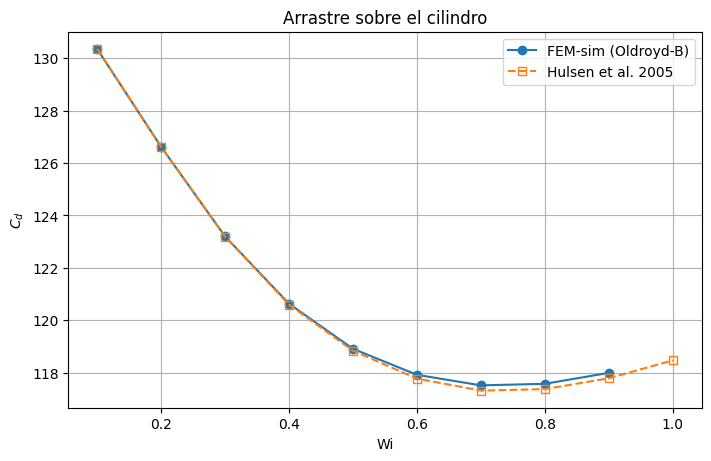

In [7]:
wi = np.array(sorted(history))
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.plot(wi, [history[w] for w in wi], 'o-', label='FEM-sim (Oldroyd-B)')
ref_wi = np.array(sorted(HULSEN))
ax.plot(ref_wi, [HULSEN[w] for w in ref_wi], 's--', mfc='none', label='Hulsen et al. 2005')
ax.set_xlabel('Wi'); ax.set_ylabel('$C_d$'); ax.set_title('Arrastre sobre el cilindro'); ax.grid(True); ax.legend()
plt.show()

## Campos para el último Wi resuelto (COMSOL muestra Wi = 0.7)

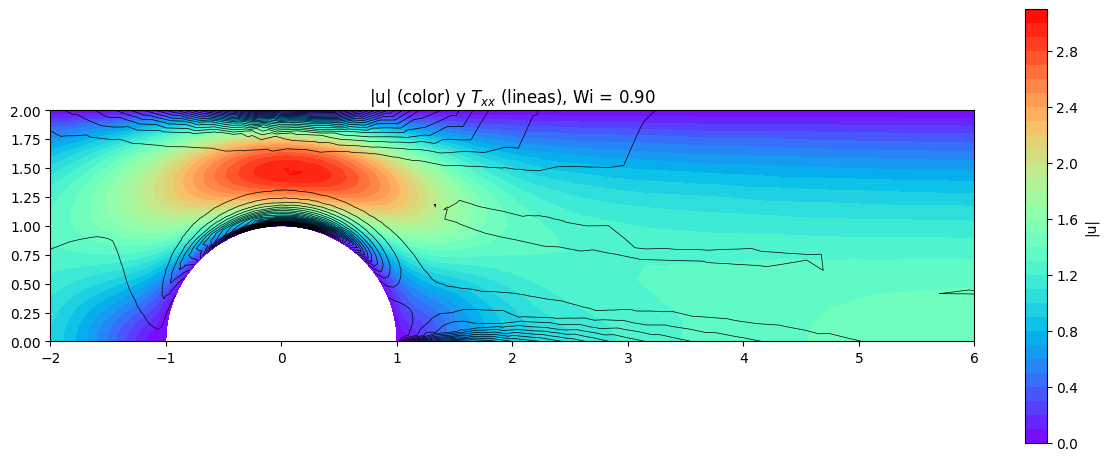

In [8]:
Wi_last = max(snapshots)
tau = snapshots[Wi_last]['tau']; u = snapshots[Wi_last]['u'].reshape(len(xy), -1)
speed = np.hypot(u[:, 0], u[:, 1])

fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
fill = ax.tricontourf(triang, speed, levels=30, cmap='rainbow')
fig.colorbar(fill, ax=ax, label='|u|')
lines = ax.tricontour(triang, tau[:, 0], levels=40, colors='k', linewidths=0.5)
ax.set_xlim(-2, 6); ax.set_ylim(0, 2); ax.set_aspect('equal')
ax.set_title(rf'|u| (color) y $T_{{xx}}$ (lineas), Wi = {Wi_last:.2f}')
plt.show()

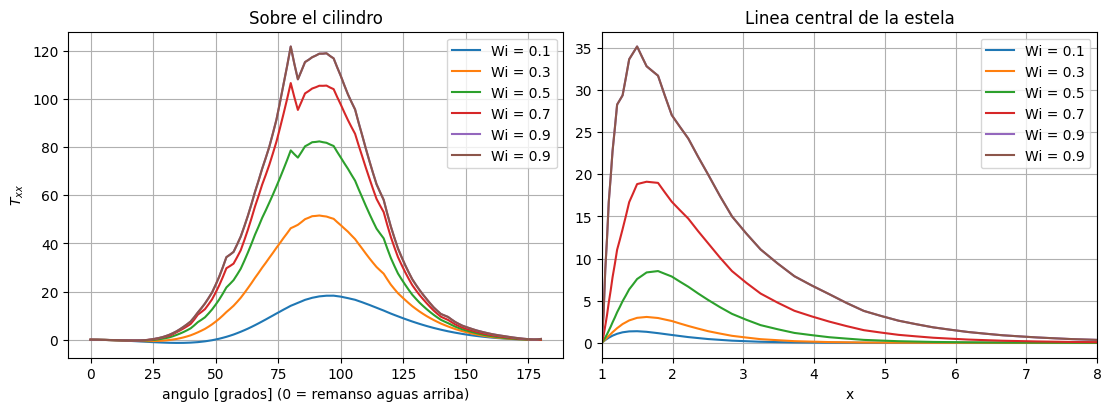

In [9]:
# Tension Txx sobre la superficie del cilindro (angulo desde el punto de remanso aguas arriba) y en la linea central de la estela
on_cyl = np.where((np.abs(np.hypot(xy[:, 0], xy[:, 1]) - R) < 1e-6) & (xy[:, 1] > -1e-9))[0]
theta = np.degrees(np.arctan2(xy[on_cyl, 1], -xy[on_cyl, 0]))
order = np.argsort(theta)
wake = np.where((np.abs(xy[:, 1]) < 1e-9) & (xy[:, 0] >= R - 1e-9))[0]
wake = wake[np.argsort(xy[wake, 0])]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for w in sorted(snapshots)[::2] + [Wi_last]:
    t = snapshots[w]['tau']
    axes[0].plot(theta[order], t[on_cyl[order], 0], label=f'Wi = {w:.1f}')
    axes[1].plot(xy[wake, 0], t[wake, 0], label=f'Wi = {w:.1f}')
axes[0].set_xlabel('angulo [grados] (0 = remanso aguas arriba)'); axes[0].set_ylabel('$T_{xx}$'); axes[0].set_title('Sobre el cilindro')
axes[1].set_xlabel('x'); axes[1].set_title('Linea central de la estela'); axes[1].set_xlim(1, 8)
for a in axes: a.grid(True); a.legend()
plt.show()